<a href="https://colab.research.google.com/github/faisalhamza909-blip/mental-health-clustering-case-study-/blob/main/mental_health_case_study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [10]:
import pandas as pd
path = "/content/drive/MyDrive/case study/mental-heath-in-tech-2016_20161114.csv"
df = pd.read_csv(path)

# Data Exploration
Here we are just exploring the data

In [11]:
df.shape

(1433, 63)

we have 1433 rows and 63 columns


In [12]:
df.head()

,Are you self-employed?,How many employees does your company or organization have?,Is your employer primarily a tech company/organization?,Is your primary role within your company related to tech/IT?,Does your employer provide mental health benefits as part of healthcare coverage?,Do you know the options for mental health care available under your employer-provided coverage?,"Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?",Does your employer offer resources to learn more about mental health concerns and options for seeking help?,Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?,"If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:",...,"If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?","If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?",What is your age?,What is your gender?,What country do you live in?,What US state or territory do you live in?,What country do you work in?,What US state or territory do you work in?,Which of the following best describes your work position?,Do you work remotely?
0,0,26-100,1.0,NaN,Not eligible for coverage / N/A,NaN,No,No,I don't know,Very easy,...,Not applicable to me,Not applicable to me,39,Male,United Kingdom,NaN,United Kingdom,NaN,Back-end Developer,Sometimes
1,0,6-25,1.0,NaN,No,Yes,Yes,Yes,Yes,Somewhat easy,...,Rarely,Sometimes,29,male,United States of America,Illinois,United States of America,Illinois,Back-end Developer|Front-end Developer,Never
2,0,6-25,1.0,NaN,No,NaN,No,No,I don't know,Neither easy nor difficult,...,Not applicable to me,Not applicable to me,38,Male,United Kingdom,NaN,United Kingdom,NaN,Back-end Developer,Always
3,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Sometimes,Sometimes,43,male,United Kingdom,NaN,United Kingdom,NaN,Supervisor/Team Lead,Sometimes
4,0,6-25,0.0,1.0,Yes,Yes,No,No,No,Neither easy nor difficult,...,Sometimes,Sometimes,43,Female,United States of America,Illinois,United States of America,Illinois,Executive Leadership|Supervisor/Team Lead|Dev ...,Sometimes


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1433 entries, 0 to 1432
Data columns (total 63 columns):
 #   Column                                                                                                                                                                            Non-Null Count  Dtype  
---  ------                                                                                                                                                                            --------------  -----  
 0   Are you self-employed?                                                                                                                                                            1433 non-null   int64  
 1   How many employees does your company or organization have?                                                                                                                        1146 non-null   object 
 2   Is your employer primarily a tech company/organization?     

Now we need to calculate the percentage of missing answers for each survey to see which column may neeed to be dropped or handled specially

In [14]:
missing_values = df.isnull()
mean_of_missing_values = missing_values.mean()
missing_percentage = mean_of_missing_values * 100



In [15]:
missing_percentage = missing_percentage.sort_values(ascending = False)
missing_percentage.head(15).round(1)

,0
"If you have revealed a mental health issue to a client or business contact, do you believe this has impacted you negatively?",90.0
"If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?",85.8
Is your primary role within your company related to tech/IT?,81.6
Do you have medical coverage (private insurance or state-provided) which includes treatment of mental health issues?,80.0
"If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to clients or business contacts?",80.0
"If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to coworkers or employees?",80.0
"If you have revealed a mental health issue to a coworker or employee, do you believe this has impacted you negatively?",80.0
Do you know local or online resources to seek help for a mental health disorder?,80.0
Do you believe your productivity is ever affected by a mental health issue?,80.0
"If maybe, what condition(s) do you believe you have?",77.5


The table that we get after runnign above shows that columns with very high missing values are mostly caused by the survey's conditional structure (for example, questions only shown to self-employed respondents). Since these are missing due to the survey's nature, they will be dropped or filtered later on.

In [16]:
print(f"Column with more than 50% missing values: {(missing_percentage > 50).sum()}")
print(f"Column with no missing values: {(missing_percentage == 0).sum()}")


Column with more than 50% missing values: 13
Column with no missing values: 19


# **Gender**

In [17]:
gender = df["What is your gender?"]
unique_genders = gender.unique()
# print(unique_genders)
print(f"Number of unique genders: {gender.nunique()}")
print(f"Missing values: {gender.isnull().sum()}")
gender.value_counts().head(20)


Number of unique genders: 70
Missing values: 3


,count
What is your gender?,
Male,610
male,249
Female,153
female,95
M,86
m,79
F,38
f,23
Male,11


The output shows that the gender column contains 70 different answer and 3 missing values, although many of them mean the same thing. For example, "Male","male","M" all refer to male and some even contain hidden spaces.


# **AGE**

In [18]:
age = df["What is your age?"]
age.describe()


,What is your age?
count,1433.000000
mean,34.286113
std,11.290931
min,3.000000
25%,28.000000
50%,33.000000
75%,39.000000
max,323.000000


In [19]:
unrealistic_ages = age[(age < 16) | (age>75)]
print(f"Number of unrealistic ages : {len(unrealistic_ages)}")
print(unrealistic_ages)

Number of unrealistic ages : 4
372     99
564    323
656      3
808     15
Name: What is your age?, dtype: int64


The age column has no missing values and the median age is 33 with most common age between 28 and 39. A few valus are unrealistic. They are most likely errors or typos or too young for regular employment. It is also very unlikely that somebody below the age of 16 would work in a tech company while 17 year olds could plausibly be interns or work voluntarily.

# Data Cleaning

In [20]:
self_employed = df['Are you self-employed?']
self_employed.value_counts()

,count
Are you self-employed?,
0,1146
1,287


In [21]:
is_employee = df['Are you self-employed?'] == 0
df_clean = df[is_employee].copy()
print(f"Rows before: {len(df)}")
print(f"Rows after: {len(df_clean)}")
print(f"self-employed: {len(df)-len(df_clean)}")


Rows before: 1433
Rows after: 1146
self-employed: 287


The dataset is filtered to employees only because the HR programme targets only the company's employees. Self-employed respondents could also not answer the employer-related questions, which caused many of the missing values. THe dataset is reduced from 1433 to 1146 respondents

In [22]:
missing_values = df_clean.isnull()
mean_of_missing_values = missing_values.mean()
missing_percentage = mean_of_missing_values * 100
# print(missing_percentage)
missing_percentage = missing_percentage.sort_values(ascending=False)
# print(missinng_percentage.head(15).round(1))
empty_columns = missing_percentage[missing_percentage == 100]
print(f"Columns that are now 100% empty: {len(empty_columns)}")
missing_percentage[missing_percentage>0].round(1)


Columns that are now 100% empty: 8


,0
Do you believe your productivity is ever affected by a mental health issue?,100.0
"If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to coworkers or employees?",100.0
"If you have revealed a mental health issue to a coworker or employee, do you believe this has impacted you negatively?",100.0
"If you have revealed a mental health issue to a client or business contact, do you believe this has impacted you negatively?",100.0
"If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to clients or business contacts?",100.0
Do you know local or online resources to seek help for a mental health disorder?,100.0
Do you have medical coverage (private insurance or state-provided) which includes treatment of mental health issues?,100.0
"If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?",100.0
"If maybe, what condition(s) do you believe you have?",78.2
Is your primary role within your company related to tech/IT?,77.1


After filtering the data, 8 columns became 100 empty since these questions were only shown to self employed respondents and contain no information for this analysis and will be dropped. Other columns still have missing values, mostly due to follow-up questions, US-only questions and some optional free test answers.

In [23]:
columns_to_drop = empty_columns.index
df_clean = df_clean.drop(columns=columns_to_drop)
print(f"Columns before: {df.shape[1]}")
print(f"Columns after: {df_clean.shape[1]}")

Columns before: 63
Columns after: 55


In [24]:
# df_clean.head()
other_columns_to_drop = [
    "Are you self-employed?",
    "Is your primary role within your company related to tech/IT?",
    "Why or why not?",
    "Why or why not?.1",
    "If maybe, what condition(s) do you believe you have?",
    "If yes, what condition(s) have you been diagnosed with?",
    "If so, what condition(s) were you diagnosed with?",
    "Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace?",
    "What US state or territory do you live in?",
    "What US state or territory do you work in?",
    "What country do you live in?"
    ]
print(f"Columns before: {df_clean.shape[1]}")
df_clean = df_clean.drop(columns=other_columns_to_drop)
print(f"Columns after: {df_clean.shape[1]}")


Columns before: 55
Columns after: 44


# Fixing Genders

In [25]:
gender_column = "What is your gender?"
df_clean[gender_column] = df_clean[gender_column].str.strip().str.lower()
print(f"Different answers after: {df_clean[gender_column].nunique()}")
df_clean[gender_column].value_counts()


Different answers after: 47


,count
What is your gender?,
male,707
female,209
m,125
f,44
woman,6
non-binary,4
man,3
cis male,3
agender,2


In [26]:
male_answers = ["male","m","cis male","male (cis)","male.","mail","dude","cisdude",
                "cis man","man", "sex is male","male (trans, ftm)"]
female_answers = ["female","f","woman","cis female","cisgender female","cis-woman",
                  "female/woman","fem","i identify as female.","female (props for making this a freeform field, though)",
                  "transgender woman", "transitioned, m2f"]
def group_gender(answer):
  if pd.isnull(answer):
    return "unknown"
  elif answer in male_answers:
    return "male"
  elif answer in female_answers:
    return "female"
  else:
    return "other"

df_clean[gender_column] = df_clean[gender_column].apply(group_gender)
df_clean[gender_column].value_counts()

,count
What is your gender?,
male,847
female,268
other,28
unknown,3


The gender column orignally contained 70 different answers. First, extra spaces were removed and all answers were converted to lower case. After performing this step the number of different answer reduced to 47 then were grouped into four categories.

# Fixing age

In [27]:
age_column = "What is your age?"
realistic_age = (df_clean[age_column]>=16) & (df_clean[age_column]<=75)
unrealistic_rows = df_clean[~realistic_age]
print(f"Removed ages: {sorted(unrealistic_rows[age_column])}")
print(f"Rows before:{len(df_clean)}")
df_clean = df_clean[realistic_age].copy()
print(f"Rows after: {len(df_clean)}")

Removed ages: [3, 99, 323]
Rows before:1146
Rows after: 1143


unrealistic ages were removed

In [28]:
missing_count = df_clean.isnull().sum()
missing_count = missing_count[missing_count>0]
print(f"Columns with missing values: {len(missing_count)}")
missing_count

Columns with missing values: 13


,0
Do you know the options for mental health care available under your employer-provided coverage?,133
Have your previous employers provided mental health benefits?,131
Were you aware of the options for mental health care provided by your previous employers?,131
Did your previous employers ever formally discuss mental health (as part of a wellness campaign or other official communication)?,131
Did your previous employers provide resources to learn more about mental health issues and how to seek help?,131
Was your anonymity protected if you chose to take advantage of mental health or substance abuse treatment resources with previous employers?,131
Do you think that discussing a mental health disorder with previous employers would have negative consequences?,131
Do you think that discussing a physical health issue with previous employers would have negative consequences?,131
Would you have been willing to discuss a mental health issue with your previous co-workers?,131
Would you have been willing to discuss a mental health issue with your direct supervisor(s)?,131


In [29]:
previous_employer_col = "Do you have previous employers?"
df_clean[previous_employer_col].value_counts()

,count
Do you have previous employers?,
1,1012
0,131


The missinv alue check shows that 13 columns stil have gaps. 11 of them have exactly 131 missing values each, and all of these are questions about previous employers. The second part shows exactly that 131 respondents have no previous employers

In [30]:
previous_employer_col = missing_count[missing_count == 131].index
df_clean[previous_employer_col] = df_clean[previous_employer_col].fillna("No previous employer")
print(f"Columnns filled: {len(previous_employer_col)}")
print(f"Missing values left in these columns: {df_clean[previous_employer_col].isnull().sum().sum()}")


Columnns filled: 11
Missing values left in these columns: 0


The 11 previous employer columns were filled with the category "No previous employer". This keeps the information that these respondents had no previous employer

In [31]:
options_col = "Do you know the options for mental health care available under your employer-provided coverage?"
benefits_col = "Does your employer provide mental health benefits as part of healthcare coverage?"
options_missing = df_clean[options_col].isnull()
df_clean.loc[options_missing, benefits_col].value_counts()


,count
Does your employer provide mental health benefits as part of healthcare coverage?,
No,72
Not eligible for coverage / N/A,55
I don't know,6


In [32]:
df_clean[options_col] = df_clean[options_col].fillna("Not applicable")
print(f"Missing values left: {df_clean[options_col].isnull().sum()}")
df_clean[options_col].value_counts()

Missing values left: 0


,count
Do you know the options for mental health care available under your employer-provided coverage?,
No,352
I am not sure,351
Yes,307
Not applicable,133


In [33]:
unsupportive_col = "Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?"
print(df_clean[unsupportive_col].value_counts(dropna=False))
df_clean[unsupportive_col] = df_clean[unsupportive_col].fillna("Not answered")
print(f"Missing values left: {df_clean.isnull().sum().sum()}")

Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?
No                    491
Maybe/Not sure        276
Yes, I observed       193
Yes, I experienced    131
NaN                    52
Name: count, dtype: int64
Missing values left: 0


The question about knowing mental health care options had 131 missng values and since the follow-up questions did not apply to them, the gaps were filled with "Not applicable". The question about observing an unsupportive response had 52 missing values. This question was skilled by the respondents and the gaps were filled with "Not answered". To avoid inventing new information seperate categories were used instead. The dataset contains no missing values now.

In [34]:
short_names = ["company_size", "tech_company", "mh_benefits", "knows_care_options",
    "employer_discussed_mh", "employer_mh_resources", "anonymity_protected", "ease_medical_leave",
    "mh_negative_consequences", "ph_negative_consequences", "comfortable_coworkers", "comfortable_supervisor",
    "employer_takes_mh_seriously", "observed_consequences_coworkers", "has_previous_employer",
    "prev_mh_benefits", "prev_aware_options", "prev_employer_discussed_mh", "prev_mh_resources",
    "prev_anonymity_protected", "prev_mh_negative_consequences", "prev_ph_negative_consequences",
    "prev_comfortable_coworkers", "prev_comfortable_supervisor", "prev_takes_mh_seriously",
    "prev_observed_consequences", "interview_physical", "interview_mental", "hurt_career",
    "coworkers_view_negatively", "share_with_family", "observed_unsupportive_response",
    "family_history", "past_disorder", "current_disorder", "diagnosed_professional",
    "sought_treatment", "interferes_treated", "interferes_untreated", "age", "gender",
    "country_work", "work_position", "remote_work",]
print(f"Number of columns: {df_clean.shape[1]}, number of new names: {len(short_names)}")
col_lookup = pd.DataFrame({"short_name": short_names, "orignal questions": df_clean.columns})
df_clean.columns = short_names
df_clean.head()

Number of columns: 44, number of new names: 44


,company_size,tech_company,mh_benefits,knows_care_options,employer_discussed_mh,employer_mh_resources,anonymity_protected,ease_medical_leave,mh_negative_consequences,ph_negative_consequences,...,current_disorder,diagnosed_professional,sought_treatment,interferes_treated,interferes_untreated,age,gender,country_work,work_position,remote_work
0,26-100,1.0,Not eligible for coverage / N/A,Not applicable,No,No,I don't know,Very easy,No,No,...,No,Yes,0,Not applicable to me,Not applicable to me,39,male,United Kingdom,Back-end Developer,Sometimes
1,6-25,1.0,No,Yes,Yes,Yes,Yes,Somewhat easy,No,No,...,Yes,Yes,1,Rarely,Sometimes,29,male,United States of America,Back-end Developer|Front-end Developer,Never
2,6-25,1.0,No,Not applicable,No,No,I don't know,Neither easy nor difficult,Maybe,No,...,No,No,1,Not applicable to me,Not applicable to me,38,male,United Kingdom,Back-end Developer,Always
4,6-25,0.0,Yes,Yes,No,No,No,Neither easy nor difficult,Yes,Maybe,...,Yes,Yes,1,Sometimes,Sometimes,43,female,United States of America,Executive Leadership|Supervisor/Team Lead|Dev ...,Sometimes
5,More than 1000,1.0,Yes,I am not sure,No,Yes,Yes,Somewhat easy,Yes,Yes,...,Yes,No,1,Not applicable to me,Often,42,male,United Kingdom,DevOps/SysAdmin|Support|Back-end Developer|Fro...,Sometimes


The 44 columns were renamed from full survey questions to short names to make the following steps and plots readable.

In [35]:
print(f"Final shape: {df_clean.shape}")
print(f"Final missing values: {df_clean.isnull().sum().sum()}")

Final shape: (1143, 44)
Final missing values: 0


# Summary
The dataset from reduced from 1433 respondents and 63 columns to 1143 employyes and 44 columns. Self-employed respondents were removed alognside empty and unusable columns were dropped, gender answers categorized into four categories, unrealistic age were removed and al remaining missing values were filled with meaningfull categories. The data is now clean and ready for encoding.

# Turning text into numbers for prog


In [36]:
for column in df_clean.columns:
  answer = df_clean[column]
  unique_answers = answer.unique()
  print(f"{column}: {len(unique_answers)} options: {unique_answers[:8]}")

company_size: 6 options: ['26-100' '6-25' 'More than 1000' '100-500' '500-1000' '1-5']
tech_company: 2 options: [1. 0.]
mh_benefits: 4 options: ['Not eligible for coverage / N/A' 'No' 'Yes' "I don't know"]
knows_care_options: 4 options: ['Not applicable' 'Yes' 'I am not sure' 'No']
employer_discussed_mh: 3 options: ['No' 'Yes' "I don't know"]
employer_mh_resources: 3 options: ['No' 'Yes' "I don't know"]
anonymity_protected: 3 options: ["I don't know" 'Yes' 'No']
ease_medical_leave: 6 options: ['Very easy' 'Somewhat easy' 'Neither easy nor difficult' 'Very difficult'
 'Somewhat difficult' "I don't know"]
mh_negative_consequences: 3 options: ['No' 'Maybe' 'Yes']
ph_negative_consequences: 3 options: ['No' 'Maybe' 'Yes']
comfortable_coworkers: 3 options: ['Maybe' 'Yes' 'No']
comfortable_supervisor: 3 options: ['Yes' 'Maybe' 'No']
employer_takes_mh_seriously: 3 options: ["I don't know" 'Yes' 'No']
observed_consequences_coworkers: 2 options: ['No' 'Yes']
has_previous_employer: 2 options: [1 

Four columns are already numeric. Two columns have a clear order without extra categories and will be encoded as ordinal numbers. Most other columns are survey answers that often include options like "I dont know","Not applicable" or "No previous employer" which do not fit on an ordered scale, so they will be one hot encoded. Two columns need special handling that are country as there are 44 diff countirs and work position almost 180 cimbinations

In [37]:
df_encoded = df_clean.copy()

company_size_order = {
     "1-5": 0,
    "6-25": 1,
    "26-100": 2,
    "100-500": 3,
    "500-1000": 4,
    "More than 1000": 5,
}

remote_work_order = {
    "Never": 0,
    "Sometimes": 1,
    "Always": 2,
}
df_encoded["company_size"] = df_encoded["company_size"].map(company_size_order)
df_encoded["remote_work"] = df_encoded["remote_work"].map(remote_work_order)
df_encoded[["company_size","remote_work"]].head()
# df_clean.head()
print(f"Missing after encoding: {df_encoded[['company_size','remote_work']].isnull().sum().sum()}")

Missing after encoding: 0


In [38]:
country_counts = df_encoded["country_work"].value_counts()
print(f"Number of couteries: {len(country_counts)}")
country_counts.head(12)

Number of couteries: 44


,count
country_work,
United States of America,714
United Kingdom,133
Canada,60
Germany,44
Netherlands,31
Australia,26
Sweden,15
France,11
Ireland,10


The dataset contains total 44 countries, but the data is heavilty US-based, only six countries have more than 25 respondents and the other 38 counteries have between 1 and 15 respondents each, which would create many almost empty columns afer one-hot encoding.

In [39]:
#big countries = atleast 25 respondents
big_countries = country_counts[country_counts>=25].index
print(f"Countries kept: {list(big_countries)}")

def group_contry(country):
  if country in big_countries:
    return country
  else:
    return "Other"

df_encoded["country_work"] = df_encoded["country_work"].apply(group_contry)
df_encoded["country_work"].value_counts()



Countries kept: ['United States of America', 'United Kingdom', 'Canada', 'Germany', 'Netherlands', 'Australia']


,count
country_work,
United States of America,714
Other,135
United Kingdom,133
Canada,60
Germany,44
Netherlands,31
Australia,26


To avoid many almost empty columns, only countries with atleast 25 respondents were kept as seperate categories and the remaining 38 countries were grouped as "Other". This reduces the country column from 44 to 7 categories while still covering the main countries which makes up around 88% of the data

In [40]:
roles = df_encoded["work_position"].str.get_dummies(sep="|")
roles.sum().sort_values(ascending=False)
roles = roles.add_prefix("role_")
df_encoded = df_encoded.drop(columns = "work_position")
df_encoded = df_encoded.join(roles)
df_encoded.shape

(1143, 55)

The work position column contained 180 different combinations. It was split into 12 seperate 0/1 columns, one per role. This way respondents who share a role are recognised as simiiar and now the dataset has 55 columns

In [41]:
text_col = df_encoded.select_dtypes(exclude="number").columns
print(f"Text columns to encode : {len(text_col)}")

df_encoded = pd.get_dummies(df_encoded, columns = text_col, dtype = int)
print(df_encoded.shape)
df_encoded.head()

Text columns to encode : 37
(1143, 168)


,company_size,tech_company,has_previous_employer,sought_treatment,age,remote_work,role_Back-end Developer,role_Designer,role_Dev Evangelist/Advocate,role_DevOps/SysAdmin,...,gender_male,gender_other,gender_unknown,country_work_Australia,country_work_Canada,country_work_Germany,country_work_Netherlands,country_work_Other,country_work_United Kingdom,country_work_United States of America
0,2,1.0,1,0,39,1,1,0,0,0,...,1,0,0,0,0,0,0,0,1,0
1,1,1.0,1,1,29,0,1,0,0,0,...,1,0,0,0,0,0,0,0,0,1
2,1,1.0,1,1,38,2,1,0,0,0,...,1,0,0,0,0,0,0,0,1,0
4,1,0.0,1,1,43,1,1,0,1,1,...,0,0,0,0,0,0,0,0,0,1
5,5,1.0,1,1,42,1,1,1,0,1,...,1,0,0,0,0,0,0,0,1,0


The remainig 37 text columns were one-hot encoded, so that each answr option became its own 0/1 column. After encoding, the dataset consists only of numbers and has 168 columns.

The columns are on very different scales. For example a 20 year-age difference would count as 20, while a different answer to question like "Does your employer offer mental health benefits ?" counts as only 1, so the age would dominate everything just because its numbers are bigger. To fix this every column will be rescaled so that its average is 0 and its spread is 1 so that every column will have the same weight

In [42]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_encoded)
df_scaled = pd.DataFrame(df_scaled, columns = df_encoded.columns, index = df_encoded.index)
print(df_scaled.shape)
print(f"Average of age after scaling: {df_scaled['age'].mean():.2f}")
print(f"Spread of age after scaling: {df_scaled['age'].std():.2f}")
df_scaled.head()

(1143, 168)
Average of age after scaling: -0.00
Spread of age after scaling: 1.00


,company_size,tech_company,has_previous_employer,sought_treatment,age,remote_work,role_Back-end Developer,role_Designer,role_Dev Evangelist/Advocate,role_DevOps/SysAdmin,...,gender_male,gender_other,gender_unknown,country_work_Australia,country_work_Canada,country_work_Germany,country_work_Netherlands,country_work_Other,country_work_United Kingdom,country_work_United States of America
0,-0.480826,0.546684,0.359787,-1.158539,0.730735,0.130249,0.952985,-0.290586,-0.278003,-0.492333,...,0.593854,-0.155543,-0.051299,-0.152567,-0.235376,-0.200091,-0.166966,-0.365963,2.755719,-1.290091
1,-1.132765,0.546684,0.359787,0.863156,-0.567617,-1.343757,0.952985,-0.290586,-0.278003,-0.492333,...,0.593854,-0.155543,-0.051299,-0.152567,-0.235376,-0.200091,-0.166966,-0.365963,-0.362882,0.775139
2,-1.132765,0.546684,0.359787,0.863156,0.600899,1.604255,0.952985,-0.290586,-0.278003,-0.492333,...,0.593854,-0.155543,-0.051299,-0.152567,-0.235376,-0.200091,-0.166966,-0.365963,2.755719,-1.290091
4,-1.132765,-1.829210,0.359787,0.863156,1.250075,0.130249,0.952985,-0.290586,3.597086,2.031148,...,-1.683915,-0.155543,-0.051299,-0.152567,-0.235376,-0.200091,-0.166966,-0.365963,-0.362882,0.775139
5,1.474990,0.546684,0.359787,0.863156,1.120240,0.130249,0.952985,3.441322,-0.278003,2.031148,...,0.593854,-0.155543,-0.051299,-0.152567,-0.235376,-0.200091,-0.166966,-0.365963,2.755719,-1.290091


# Summary
company size and remote work were encoded as ordered numbers, countries with fewer than 25 respondents were grouped as "Other", work position was split into 12 role columns, and the remaining 37 text columns were one-hot encoded and then all columnns were standardised so that each has a mean of 0 and standart deviation of 1. The dataset now has 1143 rows and 168 nnumeric columns

# Feature Selection

We check each column and will remove colums that barely vary. If it's 99% or more, the column is almost constant.

In [43]:
most_common_share = df_encoded.apply(lambda column: column.value_counts(normalize = True).iloc[0])
print(most_common_share.sort_values(ascending=False).head(10).round(3))
low_variance_columns = most_common_share[most_common_share >= 0.99].index
print(f"\nColumns to remove:{list(low_variance_columns)}")


gender_unknown                                  0.997
role_HR                                         0.991
interferes_untreated_Never                      0.991
role_Sales                                      0.990
role_One-person shop                            0.980
hurt_career_No, it has not                      0.978
country_work_Australia                          0.977
gender_other                                    0.976
prev_employer_discussed_mh_Yes, they all did    0.975
coworkers_view_negatively_Yes, they do          0.974
dtype: float64

Columns to remove:['role_HR', 'role_Sales', 'interferes_untreated_Never', 'gender_unknown']


Four columns have the same value for 99% or more of the respondents. With so few different respondents, these columns cannot help seperate meaningful groups, so they will be removed.

In [44]:
print(f"Columns before: {df_scaled.shape[1]}")
df_encoded = df_encoded.drop(columns = low_variance_columns)
df_scaled = df_scaled.drop(columns = low_variance_columns)
print(f"Columns after: {df_scaled.shape[1]}")

Columns before: 168
Columns after: 164


In [45]:
import numpy as np

correlation = df_scaled.corr().abs()
upper_half = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))
high_pairs = upper_half.stack()
high_pairs = high_pairs[high_pairs > 0.95].sort_values(ascending=False)
print(f"Pairs with correlation above 0.95: {len(high_pairs)}")
high_pairs.head(20)

Pairs with correlation above 0.95: 68


observed_consequences_coworkers_No     observed_consequences_coworkers_Yes                   1.0
has_previous_employer                  prev_mh_benefits_No previous employer                 1.0
                                       prev_employer_discussed_mh_No previous employer       1.0
                                       prev_aware_options_No previous employer               1.0
                                       prev_mh_resources_No previous employer                1.0
                                       prev_anonymity_protected_No previous employer         1.0
                                       prev_ph_negative_consequences_No previous employer    1.0
                                       prev_mh_negative_consequences_No previous employer    1.0
                                       prev_comfortable_coworkers_No previous employer       1.0
                                       prev_comfortable_supervisor_No previous employer      1.0
                                       prev_takes_mh_seriously_No previous employer          1.0
                                       prev_observed_consequences_No previous employer       1.0
prev_mh_benefits_No previous employer  prev_aware_options_No previous employer               1.0
                                       prev_employer_discussed_mh_No previous employer       1.0
                                       prev_mh_resources_No previous employer                1.0
                                       prev_anonymity_protected_No previous employer         1.0
                                       prev_mh_negative_consequences_No previous employer    1.0
                                       prev_ph_negative_consequences_No previous employer    1.0
                                       prev_comfortable_coworkers_No previous employer       1.0
                                       prev_comfortable_supervisor_No previous employer      1.0
dtype: float64

The correlation check found 68 pairs of columns with a correlation above 0.95. Most of them come from the 11 "No previous employer" columns created during one-hot encoding as they all contain exacly the same information as the column "has_previous_employer." Other are yes/no question where the "Yes" column is the exact opposite of the "No" column. In each case one column fully predicts the other, so only one of them is needed.

In [46]:
redundant_columns = [column for column in upper_half.columns if (upper_half[column] > 0.95).any()]
print(f"Redundant columns: {len(redundant_columns)}")
for column in redundant_columns:
  print(" -",column)
print(f"\nColumns before: {df_scaled.shape[1]}")
df_encoded = df_encoded.drop(columns = redundant_columns)
df_scaled = df_scaled.drop(columns = redundant_columns)
print(f"Columns after: {df_scaled.shape[1]}")

Redundant columns: 13
 - observed_consequences_coworkers_Yes
 - prev_mh_benefits_No previous employer
 - prev_aware_options_No previous employer
 - prev_employer_discussed_mh_No previous employer
 - prev_mh_resources_No previous employer
 - prev_anonymity_protected_No previous employer
 - prev_mh_negative_consequences_No previous employer
 - prev_ph_negative_consequences_No previous employer
 - prev_comfortable_coworkers_No previous employer
 - prev_comfortable_supervisor_No previous employer
 - prev_takes_mh_seriously_No previous employer
 - prev_observed_consequences_No previous employer
 - diagnosed_professional_Yes

Columns before: 164
Columns after: 151


13 redundant columns were removed and for each pair, the first column was kept and the second was removed so no information was lost

# Summary
Two checks were used to remove columns that carry little or no extra information. First, 4 columns where 99% or more of the respondents had the same value were removed (low variance). Second, 13 columns that were perfect duplocates or opposites of other columns were removed and the dataset was reduced from 168 to 151 columns.

Dimensionality reduction (PCA)

Component 1 keeps: 6.2%
Component 2 keeps: 5.2%
Fiirst 2 components together: 11.5%
Components needed for 80%: 65


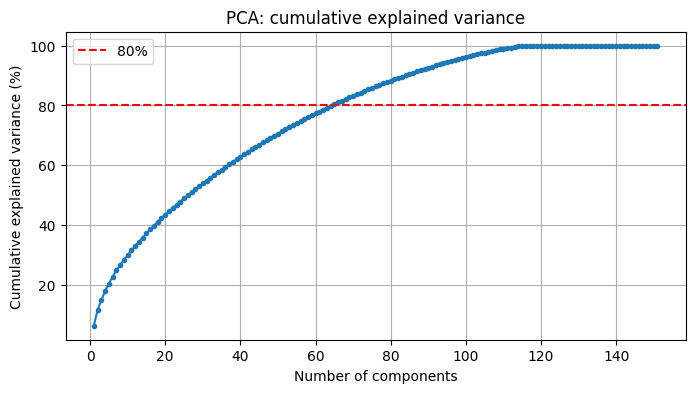

In [47]:
import os
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

figures_folder = "/content/drive/MyDrive/case study/figures"
os.makedirs(figures_folder, exist_ok=True)

pca_full = PCA()
pca_full.fit(df_scaled)
explained = pca_full.explained_variance_ratio_ * 100
cumulative = np.cumsum(explained)

print(f"Component 1 keeps: {explained[0]:.1f}%")
print(f"Component 2 keeps: {explained[1]:.1f}%")
print(f"Fiirst 2 components together: {cumulative[1]:.1f}%")
print(f"Components needed for 80%: {np.argmax(cumulative >= 80) + 1}")

plt.figure(figsize=(8,4))
plt.plot(range(1, len(cumulative) + 1), cumulative, marker=".")
plt.axhline(80, color="red", linestyle="--", label="80%")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance (%)")
plt.title("PCA: cumulative explained variance")
plt.legend()
plt.grid(True)
plt.savefig(f"{figures_folder}/pca_explained_variance.png", dpi=150, bbox_inches="tight")
plt.show()

The first two component explain only 11.5% of the variance and the curve rises gradually with a clear bend. This shows that the information is spread across many components, which is typical for survey data with many seperate categorical answers. for 80% of the variance 65 components are needed will these components will be used for clustering, which reduces the data from 151 to 65 dimensions while keeping the most of the information and the first two components will only be used for visualisation.

Shape after PCA: (1143, 65)
Information kept: 80.1%


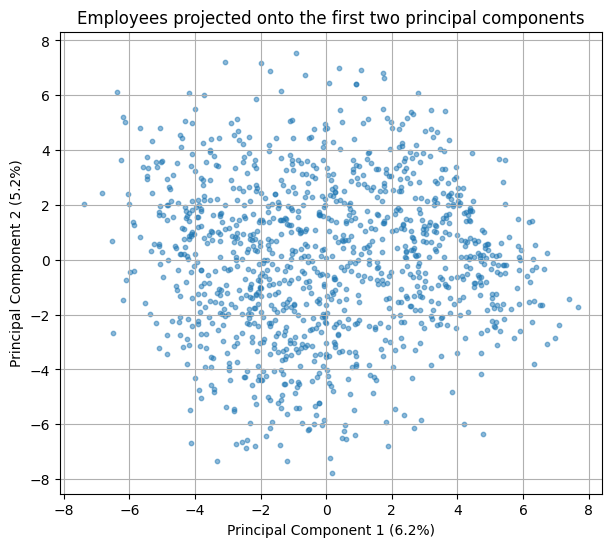

In [48]:
pca = PCA(n_components=65)
pca_data = pca.fit_transform(df_scaled)
print(f"Shape after PCA: {pca_data.shape}")
print(f"Information kept: {pca.explained_variance_ratio_.sum()*100:.1f}%")

plt.figure(figsize=(7,6))
plt.scatter(pca_data[:,0], pca_data[:,1], s=10, alpha=0.5)
plt.xlabel("Principal Component 1 (6.2%)")
plt.ylabel("Principal Component 2 (5.2%)")
plt.title("Employees projected onto the first two principal components")
plt.grid(True)
plt.savefig(f"{figures_folder}/pca_2d_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

The 2D scatter plot of the first two principal componenTs shows one large cloud without clearly seperated groups. Since these two components only contain 11.5% of the variance; differences between the groups may exist in the other dimensions. It also sugguests that employee groups in this survey are likely to overlap rather than being sharply seperated, which should be considered when interpreting the clusters. The plot wil be used again after clustering, which each employee coloured by their cluster.

MDS

Shape after MDS: (1143, 2)


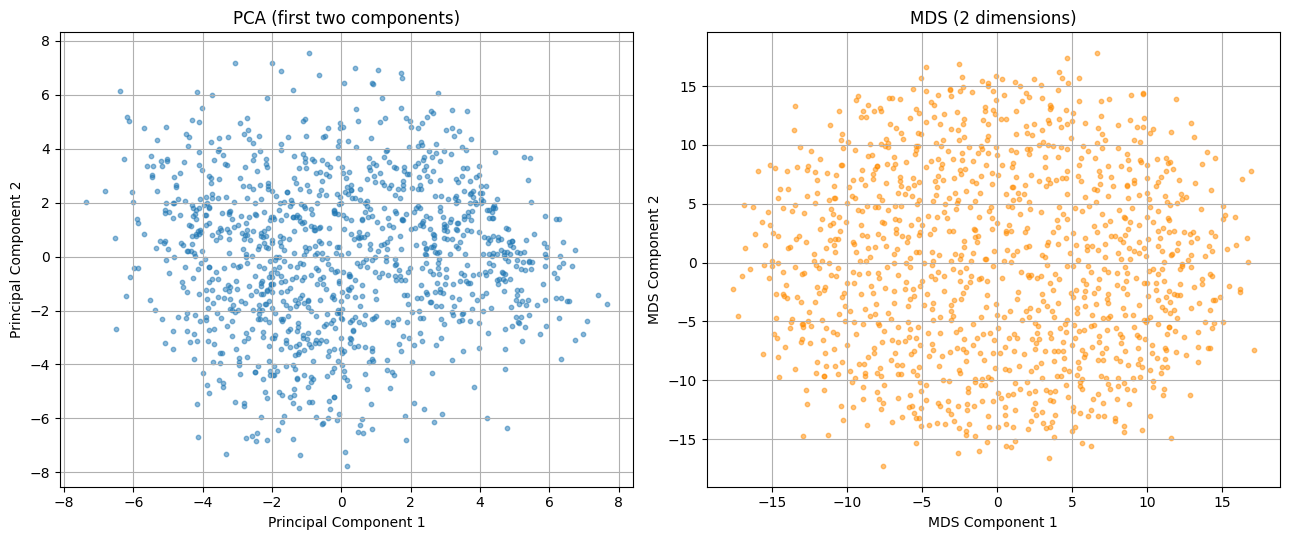

In [49]:
from sklearn.manifold import MDS
mds = MDS(n_components=2, random_state=42, n_init=1)
mds_data = mds.fit_transform(df_scaled)
print(f"Shape after MDS: {mds_data.shape}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

axes[0].scatter(pca_data[:,0], pca_data[:,1], s=10, alpha=0.5)
axes[0].set_title("PCA (first two components)")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
axes[0].grid(True)

axes[1].scatter(mds_data[:,0], mds_data[:,1], s=10, alpha=0.5, color ="darkorange")
axes[1].set_title("MDS (2 dimensions)")
axes[1].set_xlabel("MDS Component 1")
axes[1].set_ylabel("MDS Component 2")
axes[1].grid(True)

plt.tight_layout()
plt.savefig(f"{figures_folder}/pca_vs_mds.png", dpi=150, bbox_inches="tight")
plt.show()

metric MDS was applied for a second dimensionality reduction method, which places employees in 2D so that their original distances are preserved as well as possible. Like PCA,MDS shows one large cloud without clearly seperated groups. Because two different methods lead to the same picture, this is a property of the data rather than of a single method. MDS spreads the points more evenly than PCA, which is typical for high-dimensional data, where most distances between respondents are similiar.

# Summary
PCA reduced the 151 columns to 65 components that keep 80% of the variance. Both PCA and MDS show one continuos cloud without clear gaps, suggesting that the clusters found in the next step will be overlapping employee types rather than strictly seperated groupus

# **Clustering**

k=2: inertia=130144, silhouette=0.057
k=3: inertia=125587, silhouette=0.053
k=4: inertia=122830, silhouette=0.047
k=5: inertia=120482, silhouette=0.046
k=6: inertia=118449, silhouette=0.044
k=7: inertia=116897, silhouette=0.042
k=8: inertia=115000, silhouette=0.042
k=9: inertia=113809, silhouette=0.042
k=10: inertia=112795, silhouette=0.035


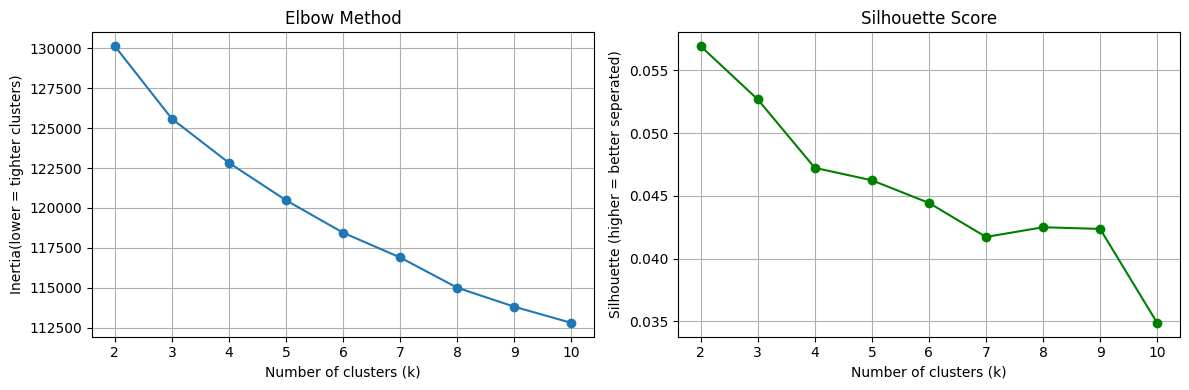

In [50]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias = []
silhouettes = []
k_values = range(2,11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(pca_data)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(pca_data, labels))
    print(f"k={k}: inertia={kmeans.inertia_:.0f}, silhouette={silhouettes[-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(k_values, inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia(lower = tighter clusters)")
axes[0].grid(True)

axes[1].plot(k_values, silhouettes, marker="o",color ="green")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette (higher = better seperated)")
axes[1].grid(True)

plt.tight_layout()
plt.savefig(f"{figures_folder}/elbow_silhouette.png", dpi=150, bbox_inches="tight")
plt.show()




The elbow curve decreaese steadily without a sharp bend;

Silhouette score (k=3): 0.053
cluster
0    323
1    430
2    390
Name: count, dtype: int64


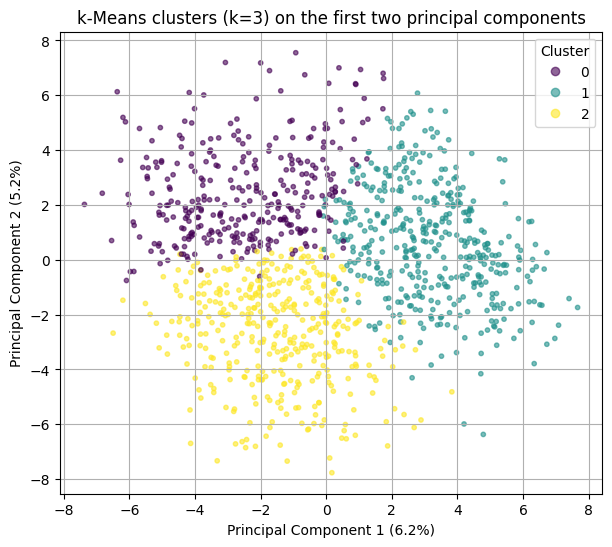

In [51]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(pca_data)

df_clean["cluster"] = cluster_labels

print(f"Silhouette score (k=3): {silhouette_score(pca_data, cluster_labels):.3f}")
print(df_clean["cluster"].value_counts().sort_index())

plt.figure(figsize=(7, 6))
scatter = plt.scatter(pca_data[:, 0], pca_data[:, 1], c=cluster_labels, cmap="viridis", s=10, alpha=0.6)
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.xlabel("Principal Component 1 (6.2%)")
plt.ylabel("Principal Component 2 (5.2%)")
plt.title("k-Means clusters (k=3) on the first two principal components")
plt.grid(True)
plt.savefig(f"{figures_folder}/kmeans_clusters_pca.png", dpi=150, bbox_inches="tight")
plt.show()

K-Means with 3 clusters divides the 1,143 employees into groups of 323, 430 and 390 respondents. The silhouette score is 0.053. In the PCA plot, the three clusters occupy different regions of the cloud (top left, right and bottom), but their borders touch without a clear gap. The clusters are therefore distinct but overlapping employee profiles. The cluster number of each employee was added to df_clean, so that the clusters can be described using the original answers in the next step.

In [53]:
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

for shape in ["full", "spherical"]:
    gmm = GaussianMixture(n_components=3, covariance_type=shape, random_state=42, n_init=5)
    gmm_labels = gmm.fit_predict(pca_data)

    print(f"--- GMM ({shape}) ---")
    print(f"Cluster sizes: {np.bincount(gmm_labels)}")
    print(f"Silhouette score: {silhouette_score(pca_data, gmm_labels):.3f}")
    print(f"Agreement with k-Means (ARI): {adjusted_rand_score(cluster_labels, gmm_labels):.3f}")
    print(pd.crosstab(cluster_labels, gmm_labels, rownames=["k-Means"], colnames=["GMM"]))
    print()


--- GMM (full) ---
Cluster sizes: [395 353 395]
Silhouette score: 0.032
Agreement with k-Means (ARI): 0.253
GMM        0    1    2
k-Means               
0        177    1  145
1        187  243    0
2         31  109  250

--- GMM (spherical) ---
Cluster sizes: [337 378 428]
Silhouette score: 0.052
Agreement with k-Means (ARI): 0.903
GMM        0    1    2
k-Means               
0        313    0   10
1          7    5  418
2         17  373    0



To check the stability of the cluster, a Gaussian Mixture Model (GMM) with 3 components was applied as a second method. With spherical clusters, the GMM finds almost the same group as k-Means and a similiar silhouette score. With full covariance, the GMM agrees much less and seperates the data worse. This is because full covariance requires estimating a very large number of parameters in 65 dimensions, which is not reliable with only 1143 respondents. Since two different algorithms find the same three groups, the k-mean clusters are considered stable and are used for the interpretation.